In [7]:
import matplotlib.pyplot as plt
import numpy as np

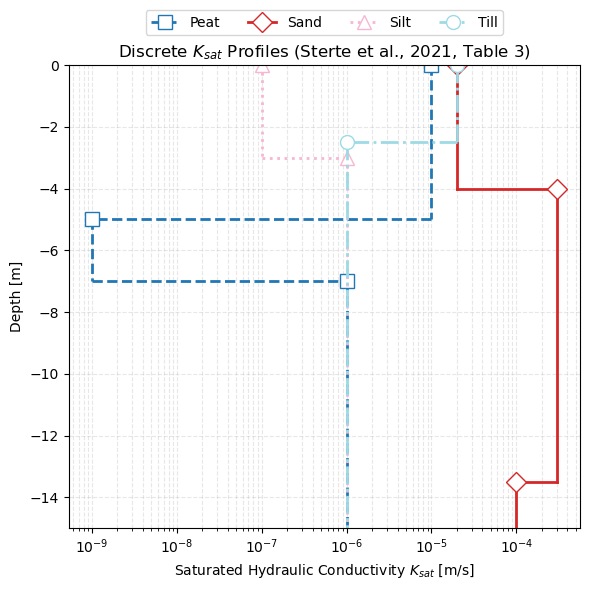

In [13]:
soil_profiles = {
    "Till": [(0, 2.5, 2e-5), (2.5, 15, 1e-6)],
    "Peat": [(0, 5, 1e-5), (5, 7, 1e-9), (7, 15, 1e-6)],
    "Silt": [(0, 3, 1e-7), (3, 15, 1e-6)],
    "Sand": [(0, 4, 2e-5), (4, 0.9 * 15, 3e-4), (0.9 * 15, 15, 1e-4)],
}
line_styles = {"Peat": "--", "Silt": ":", "Till": "-.", "Sand": "-"}
markers = {"Peat": "s", "Silt": "^", "Till": "o", "Sand": "D"}

fig, ax = plt.subplots(figsize=(6, 6))
soil_types = sorted(soil_profiles)
colors = plt.cm.tab20(np.linspace(0, 1, len(soil_types)))

for color, soil_type in zip(colors, soil_types):
    layers = soil_profiles[soil_type]
    line_style = line_styles[soil_type]
    previous_ksat = None
    for layer_index, (top, bottom, ksat) in enumerate(layers):
        if previous_ksat is not None:
            # Connect adjacent layers horizontally at their shared depth boundary.
            ax.plot([previous_ksat, ksat], [-top, -top], color=color, alpha=1.0, linewidth=2, linestyle=line_style)
        ax.plot(
            [ksat, ksat], [-top, -bottom],
            color=color, linewidth=2, linestyle=line_style,
            marker=markers[soil_type], markevery=[0], markersize=10,
            markerfacecolor="white", markeredgecolor=color,
            label=soil_type if layer_index == 0 else None,
        )
        previous_ksat = ksat

ax.set_xscale("log")
ax.set_ylim(-15, 0)
ax.set_xlabel("Saturated Hydraulic Conductivity $K_{sat}$ [m/s]")
ax.set_ylabel("Depth [m]")
ax.set_title("Discrete $K_{sat}$ Profiles (Sterte et al., 2021, Table 3)")
ax.grid(True, which="both", alpha=0.3, linestyle="--")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.05), ncol=4)
fig.tight_layout()
plt.show()